# A5 - Uptake and Participation

This notebook uses the enhanced LLM codes to answer RQ2: **whose ideas are taken up and developed in co-constructive exchanges, and how is this participation distributed across students and languages?**

It takes the enhanced LLM codes as given, following the plan for this assignment, and reads them alongside the transcript (for each line's language) and the GCA scores. A4 showed what that assumption costs: against our adjudicated codes the enhanced prompt matched Whose on 72–82% of turns, and its most common error was reading uptake phrased as a student's own answer as Self. Co-construction is therefore more likely undercounted than overcounted here, and every result below should be read with that in mind.

Sections:

1. Load the LLM codes, the transcript, and the GCA scores
2. Build turns and uptake events from the LLM's `turn` and `builds_on` columns
3. Whose ideas are taken up: uptake received by each student, and who builds on whom
4. How participation is distributed: shares and Gini coefficients
5. Language: whether ideas offered in Spanish, English, or both are taken up at different rates
6. GCA: whether students with more LLM-coded uptake also have higher GCA social impact

Run it from the top of the repository. The transcript and metadata are read from `Data/Track A/`, which git ignores. Outputs go to `results/uptake_participation/` and contain codes, counts, and scores only, no transcript text.

## Settings

To run on new LLM outputs, point `LLM_OUTPUTS` at the new files. Each file needs one row per transcript line with at least `observation, row, speaker, turn, whose, builds_on, level` (extra columns such as `reason` are ignored). `row` is the segment letter plus the line number, for example `c12`.

In [1]:
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch

sys.path.append("analysis")
from a4_turns import clean, last_code

LLM_OUTPUTS = sorted(Path("results/comparison_data").glob("llm_enhanced_*.csv"))
TRANSCRIPT = Path("Data/Track A/all_observations_combined.csv")
METADATA = Path("Data/Track A/observation_metadata.csv")
GCA_SCORES = Path("Data/Track A/gca_outputs/embeddings_w3/gca_student_scores.csv")

OUTPUT_DIR = Path("results") / "uptake_participation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DEVELOPED_LEVELS = {"medium", "high"}  # co-construction, as defined in A4
UNNAMED_STUDENT = "Other"  # the transcripts' label for a student who is not named in the metadata
LANGUAGES = ["English", "Spanish", "Both"]

## 1. Load the data

- **LLM codes**: one row per transcript line.
- **Transcript**: only `observation`, `segment`, `#`, `speaker`, and `named_language` are kept; the dialogue is never read into the results. Languages other than English, Spanish, and Both (a few stray codes) are treated as unknown.
- **Metadata**: the named students in each observation, the same lookup the A3 GCA notebook uses. The speaker "Other" is a student who is not named in the metadata; anyone else is an adult.
- **GCA scores**: per-student scores from `A3 - Methods.ipynb` run with multilingual embeddings and a window of three. This file is optional: without it, section 6 is skipped.

In [2]:
llm = pd.concat([pd.read_csv(path, keep_default_na=False, dtype=str) for path in LLM_OUTPUTS], ignore_index=True)
observations = sorted(llm["observation"].unique())

transcript = pd.read_csv(TRANSCRIPT, usecols=["observation", "segment", "#", "speaker", "named_language"],
                         dtype=str, keep_default_na=False)
transcript = transcript[transcript["observation"].isin(observations)].copy()
transcript["row"] = transcript["segment"] + transcript["#"]
transcript["language"] = transcript["named_language"].where(transcript["named_language"].isin(LANGUAGES), "Unknown")

metadata = pd.read_csv(METADATA, usecols=["obs_index", "teacher_pseudonym", "student_pseudonyms"],
                       dtype=str, keep_default_na=False)
metadata["observation"] = metadata["obs_index"].str.strip().str.replace(r"^OBS-", "OBS_", regex=True)
named_students = {
    observation: set(re.findall(r"'([^']+)'", names or ""))
    for observation, names in zip(metadata["observation"], metadata["student_pseudonyms"])
}

lines = llm.merge(transcript[["observation", "row", "language"]], on=["observation", "row"], how="left")
missing_language = lines["language"].isna().sum()
lines["language"] = lines["language"].fillna("Unknown")


def role(observation, speaker):
    if speaker in named_students.get(observation, set()):
        return "Student"
    return "Unnamed student" if speaker == UNNAMED_STUDENT else "Adult"


lines["role"] = [role(o, s) for o, s in zip(lines["observation"], lines["speaker"])]
for column in ["whose", "level"]:
    lines[column] = lines[column].map(clean)

print(f"{len(LLM_OUTPUTS)} LLM files, {len(observations)} observations, {len(lines)} lines")
print(f"Lines without a transcript match: {missing_language}")
pd.crosstab(lines["observation"], lines["role"])

2 LLM files, 2 observations, 248 lines
Lines without a transcript match: 0


role,Adult,Student,Unnamed student
observation,,,
OBS_26-0498,34,55,8
OBS_26-0515,29,122,0


## 2. Turns and uptake events

**Turns** come from the LLM's own `turn` IDs, because that is how the enhanced prompt grouped lines into one mathematical thought. A turn's Whose is the last Whose on its lines, its Level is the last Level, and its language is the language of its lines: English, Spanish, or Both when its lines mix languages or a line is coded Both.

**Uptake events** come from `builds_on`. Every Other turn names the row or rows it builds on, for example `Gregorio a6`, `Miguel c24-c27`, or `Other c11 and Miguel c24`. The parser finds every row ID in the text and takes the source speaker from the transcript, not from the name the LLM wrote, so a misspelled or missing name cannot misattribute an event. A cited range counts once, at its first row. Each event links a **source** (the student whose idea is taken up) to a **responder** (the student building on it), with the responder's Level. An event is **developed** when that Level is Medium or High, the A4 definition of co-construction; otherwise it is **acknowledged** (Low or no Level).

In [3]:
ROW_PATTERN = re.compile(r"\b([a-z])(\d+)(?:\s*[-–]\s*[a-z]?\d+)?\b")


def turn_language(values):
    known = {value for value in values if value != "Unknown"}
    if not known:
        return "Unknown"
    if known == {"English"}:
        return "English"
    if known == {"Spanish"}:
        return "Spanish"
    return "Both"


student_lines = lines[(lines["role"] != "Adult") & (lines["turn"] != "")]
row_speaker = lines.set_index(["observation", "row"])["speaker"]
row_turn = student_lines.set_index(["observation", "row"])["turn"]

turns = (
    student_lines.groupby(["observation", "turn"], sort=False)
    .agg(rows=("row", " ".join), speaker=("speaker", "last"), role=("role", "last"),
         whose=("whose", last_code), level=("level", last_code), language=("language", turn_language),
         builds_on=("builds_on", lambda values: " | ".join(v for v in values if v)))
    .reset_index()
)
turns["developed"] = (turns["whose"] == "other") & turns["level"].isin(DEVELOPED_LEVELS)

events, parse_log = [], []
for _, turn in turns[turns["whose"] == "other"].iterrows():
    cited = []
    for match in ROW_PATTERN.finditer(turn["builds_on"]):
        row = match.group(1) + match.group(2)
        if (turn["observation"], row) in row_speaker.index and row not in cited:
            cited.append(row)
    if not cited:
        parse_log.append({"observation": turn["observation"], "turn": turn["turn"],
                          "builds_on": turn["builds_on"], "problem": "no row ID found"})
    for row in cited:
        source = row_speaker[(turn["observation"], row)]
        if source == turn["speaker"]:
            parse_log.append({"observation": turn["observation"], "turn": turn["turn"], "builds_on": turn["builds_on"],
                              "problem": f"row {row} is the responder's own line; not counted"})
            continue
        if source not in turn["builds_on"]:
            parse_log.append({"observation": turn["observation"], "turn": turn["turn"], "builds_on": turn["builds_on"],
                              "problem": f"row {row} is spoken by {source}, who is not named"})
        events.append({
            "observation": turn["observation"],
            "responder_turn": turn["turn"],
            "responder": turn["speaker"],
            "responder_language": turn["language"],
            "source_row": row,
            "source_turn": row_turn.get((turn["observation"], row), ""),
            "source": source,
            "source_role": role(turn["observation"], source),
            "level": turn["level"],
            "developed": turn["developed"],
        })

events = pd.DataFrame(events)
language_by_turn = turns.set_index(["observation", "turn"])["language"]
events["source_language"] = [language_by_turn.get((o, t), "Unknown")
                             for o, t in zip(events["observation"], events["source_turn"])]
parse_log = pd.DataFrame(parse_log, columns=["observation", "turn", "builds_on", "problem"])

turns.drop(columns="builds_on").to_csv(OUTPUT_DIR / "turns.csv", index=False)
events.to_csv(OUTPUT_DIR / "uptake_events.csv", index=False)
parse_log.to_csv(OUTPUT_DIR / "builds_on_parse_log.csv", index=False)

print(f"{len(turns)} student turns, {int((turns['whose'] == 'other').sum())} Other turns, {len(events)} uptake events")
print(f"Events whose source is an adult: {int((events['source_role'] == 'Adult').sum())}")
parse_log

82 student turns, 25 Other turns, 26 uptake events
Events whose source is an adult: 0


,observation,turn,builds_on,problem


## 3. Whose ideas are taken up

For each student in each observation:

- **Self turns**: ideas the student offered as their own.
- **Uptake received**: events where a peer builds on one of the student's lines, split into developed and acknowledged.
- **Self turns taken up**: the share of the student's Self turns that at least one peer later builds on.

Adults are left out: the codebook's Other means building on a peer's idea, so an event with an adult source would be a coding error; the cell above reports how many there are.

In [4]:
peer_events = events[events["source_role"] != "Adult"]
taken_up_turns = set(zip(peer_events["observation"], peer_events["source_turn"]))
turns["taken_up"] = [(o, t) in taken_up_turns for o, t in zip(turns["observation"], turns["turn"])]

students = (
    turns.groupby(["observation", "speaker", "role"])
    .agg(turns=("turn", "size"),
         self_turns=("whose", lambda w: int((w == "self").sum())),
         other_turns=("whose", lambda w: int((w == "other").sum())),
         developed_turns=("developed", "sum"))
    .reset_index()
)
received = (
    peer_events.groupby(["observation", "source"])
    .agg(uptake_received=("developed", "size"), developed_received=("developed", "sum"))
    .rename_axis(["observation", "speaker"])
)
self_taken_up = (
    turns[turns["whose"] == "self"].groupby(["observation", "speaker"])["taken_up"].sum()
    .rename("self_turns_taken_up")
)
students = (
    students.set_index(["observation", "speaker"])
    .join(received).join(self_taken_up)
    .fillna({"uptake_received": 0, "developed_received": 0, "self_turns_taken_up": 0})
    .reset_index()
)
for column in ["uptake_received", "developed_received", "self_turns_taken_up", "developed_turns"]:
    students[column] = students[column].astype(int)
students["acknowledged_received"] = students["uptake_received"] - students["developed_received"]
students["share_of_self_taken_up"] = students["self_turns_taken_up"] / students["self_turns"].replace(0, np.nan)

students.to_csv(OUTPUT_DIR / "students.csv", index=False)
students

,observation,speaker,role,turns,self_turns,other_turns,developed_turns,uptake_received,developed_received,self_turns_taken_up,acknowledged_received,share_of_self_taken_up
0,OBS_26-0498,Gregorio,Student,20,4,5,5,4,2,2,2,0.500000
1,OBS_26-0498,Miguel,Student,19,5,4,2,5,3,1,2,0.200000
2,OBS_26-0498,Other,Unnamed student,7,2,3,1,4,4,2,0,1.000000
3,OBS_26-0515,Gregorio,Student,20,14,6,1,7,4,4,3,0.285714
4,OBS_26-0515,Miguel,Student,16,9,7,4,6,1,3,5,0.333333


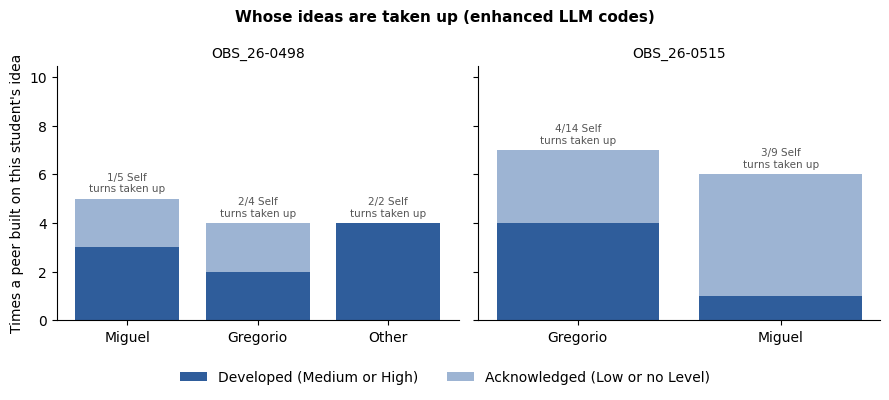

In [5]:
def save_table_image(frame, path, title, font_size=9):
    figure, axis = plt.subplots(figsize=(4, 0.3 * (len(frame) + 2)))
    axis.axis("off")
    shown = axis.table(cellText=frame.astype(str).values, colLabels=frame.columns,
                       cellLoc="left", colLoc="left", loc="upper left")
    shown.auto_set_font_size(False)
    shown.set_fontsize(font_size)
    shown.auto_set_column_width(list(range(frame.shape[1])))
    shown.scale(1, 1.4)
    for (row, column), cell in shown.get_celld().items():
        cell.set_edgecolor("#d0d0d0")
        if row == 0:
            cell.set_facecolor("#eef2f7")
            cell.set_text_props(weight="bold")
    axis.set_title(title, loc="left", fontsize=11, weight="bold")
    figure.savefig(path, dpi=200, bbox_inches="tight")
    plt.close(figure)


def fraction(part, whole):
    return f"{part}/{whole} ({part / whole:.0%})" if whole else "0/0"


uptake_table = pd.DataFrame({
    "Observation": students["observation"],
    "Student": students["speaker"],
    "Self turns": students["self_turns"],
    "Uptake received": students["uptake_received"],
    "Developed (Medium+)": students["developed_received"],
    "Self turns taken up": [fraction(a, b) for a, b in zip(students["self_turns_taken_up"], students["self_turns"])],
})
save_table_image(uptake_table, OUTPUT_DIR / "uptake_by_student.png", "Whose ideas are taken up, by student")

COLORS = {"developed": "#2f5d9b", "acknowledged": "#9db4d3"}
figure, axes = plt.subplots(1, len(observations), figsize=(4.5 * len(observations), 3.8), sharey=True, squeeze=False)
for axis, observation in zip(axes[0], observations):
    shown = students[students["observation"] == observation].sort_values("uptake_received", ascending=False)
    x = np.arange(len(shown))
    axis.bar(x, shown["developed_received"], color=COLORS["developed"], label="Developed (Medium or High)")
    axis.bar(x, shown["acknowledged_received"], bottom=shown["developed_received"],
             color=COLORS["acknowledged"], label="Acknowledged (Low or no Level)")
    for position, (_, student) in zip(x, shown.iterrows()):
        axis.text(position, student["uptake_received"] + 0.2,
                  f"{student['self_turns_taken_up']}/{student['self_turns']} Self\nturns taken up",
                  ha="center", va="bottom", fontsize=7.5, color="#555555")
    axis.set_xticks(x)
    axis.set_xticklabels(shown["speaker"])
    axis.set_title(observation, fontsize=10)
    axis.spines[["top", "right"]].set_visible(False)
axes[0][0].set_ylabel("Times a peer built on this student's idea")
axes[0][0].set_ylim(0, students["uptake_received"].max() * 1.35 + 1)
handles, labels = axes[0][0].get_legend_handles_labels()
figure.legend(handles, labels, loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.04))
figure.suptitle("Whose ideas are taken up (enhanced LLM codes)", fontsize=11, weight="bold")
figure.tight_layout(rect=(0, 0.06, 1, 1))
figure.savefig(OUTPUT_DIR / "uptake_by_student_bars.png", dpi=200, bbox_inches="tight")
plt.show()

### Who builds on whom

One network per observation. An arrow from A to B means B built on A's idea; its width is the number of events, and its label gives all events with the developed ones in parentheses. The matrix of the same counts is saved as `uptake_matrix.csv`.

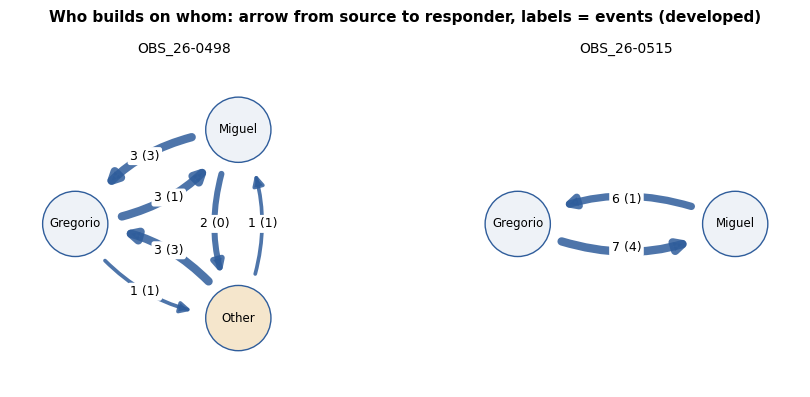

In [6]:
matrix = (
    peer_events.groupby(["observation", "source", "responder"])
    .agg(events=("developed", "size"), developed=("developed", "sum"))
    .reset_index()
)
matrix.to_csv(OUTPUT_DIR / "uptake_matrix.csv", index=False)


def plot_network(axis, observation):
    edges = matrix[matrix["observation"] == observation]
    people = sorted(set(students.loc[students["observation"] == observation, "speaker"]))
    angles = np.linspace(np.pi, -np.pi, len(people), endpoint=False)
    positions = {person: (np.cos(angle), np.sin(angle)) for person, angle in zip(people, angles)}
    widest = max(edges["events"].max() if len(edges) else 1, 1)

    for _, edge in edges.iterrows():
        start, end = positions[edge["source"]], positions[edge["responder"]]
        axis.add_patch(FancyArrowPatch(start, end, connectionstyle="arc3,rad=0.25", arrowstyle="-|>",
                                       mutation_scale=16, lw=1 + 5 * edge["events"] / widest,
                                       color="#2f5d9b", shrinkA=34, shrinkB=34, alpha=0.85))
        middle = np.add(start, end) / 2
        normal = np.array([end[1] - start[1], start[0] - end[0]])
        normal = normal / (np.linalg.norm(normal) or 1)
        label_at = middle + 0.22 * normal
        axis.text(*label_at, f"{edge['events']} ({edge['developed']})", ha="center", va="center", fontsize=9,
                  bbox={"boxstyle": "round,pad=0.2", "facecolor": "white", "edgecolor": "none"})

    for person, (x, y) in positions.items():
        color = "#eef2f7" if role(observation, person) == "Student" else "#f5e6cc"
        axis.add_patch(plt.Circle((x, y), 0.3, facecolor=color, edgecolor="#2f5d9b", zorder=3))
        axis.text(x, y, person, ha="center", va="center", fontsize=8.5, zorder=4)

    axis.set_xlim(-1.6, 1.6)
    axis.set_ylim(-1.5, 1.5)
    axis.set_aspect("equal")
    axis.axis("off")
    axis.set_title(observation, fontsize=10)


figure, axes = plt.subplots(1, len(observations), figsize=(4.5 * len(observations), 4), squeeze=False)
for axis, observation in zip(axes[0], observations):
    plot_network(axis, observation)
figure.suptitle("Who builds on whom: arrow from source to responder, labels = events (developed)",
                fontsize=11, weight="bold")
figure.tight_layout()
figure.savefig(OUTPUT_DIR / "uptake_network.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. How participation is distributed

Within each observation, each student's share of four things: all turns, Self turns, developed (co-construction) turns, and developed uptake received. The **Gini coefficient** summarizes how unevenly each is spread across the observation's students: 0 means every student has the same amount, and values near 1 mean one student has almost all of it. With two students, the Gini equals half the difference between their shares, so it is easy to read back.

The unnamed student labeled "Other" is included when they spoke, because the LLM coded their turns too; the Gini table reports the number of students it is computed over.

In [7]:
def gini(values):
    values = np.asarray(values, dtype=float)
    if len(values) == 0 or values.sum() == 0:
        return np.nan
    return np.abs(values[:, None] - values[None, :]).sum() / (2 * len(values) ** 2 * values.mean())


MEASURES = {"turns": "All turns", "self_turns": "Self turns", "developed_turns": "Developed turns",
            "developed_received": "Developed uptake received"}

for column in MEASURES:
    students[f"{column}_share"] = students[column] / students.groupby("observation")[column].transform("sum")

gini_table = pd.DataFrame([
    {"Observation": observation, "Students": len(group),
     **{label: round(gini(group[column]), 2) for column, label in MEASURES.items()}}
    for observation, group in students.groupby("observation")
])
gini_table.to_csv(OUTPUT_DIR / "gini.csv", index=False)
save_table_image(gini_table, OUTPUT_DIR / "gini.png", "Gini coefficient across students (0 = equal)")
students.to_csv(OUTPUT_DIR / "students.csv", index=False)
gini_table

,Observation,Students,All turns,Self turns,Developed turns,Developed uptake received
0,OBS_26-0498,3,0.19,0.18,0.33,0.15
1,OBS_26-0515,2,0.06,0.11,0.30,0.30


/var/folders/2w/ty1dqwyx6q7cfznbvxqrl7th0000gp/T/ipykernel_42728/825581897.py:9: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  shares = shown.loc[person, [f"{column}_share" for column in MEASURES]].fillna(0).values.astype(float)
/var/folders/2w/ty1dqwyx6q7cfznbvxqrl7th0000gp/T/ipykernel_42728/825581897.py:9: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  shares = shown.loc[person, [f"{column}_share" for column in MEASURES]].fillna(0).values.astype(float)
/var/folders/2w/ty1dqwyx6q7cfznbvxqrl7th0000gp/T/ipykernel_42728/825581897.py:9: FutureWarning: Downca

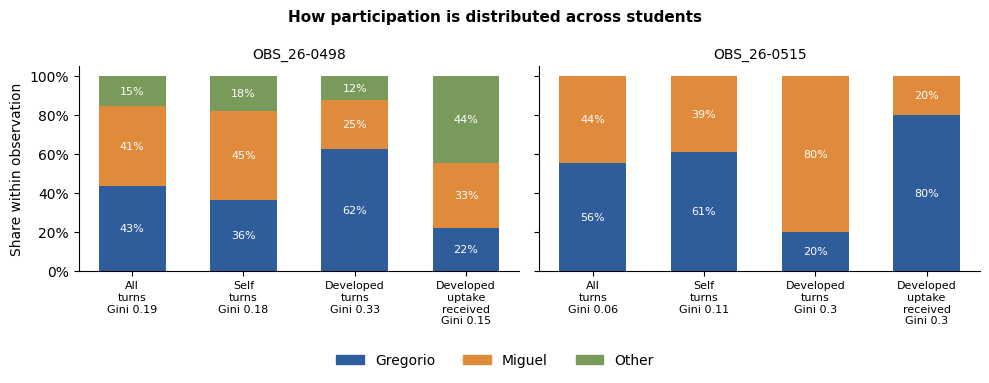

In [8]:
people = sorted(students["speaker"].unique())
palette = dict(zip(people, ["#2f5d9b", "#e08a3c", "#7a9a5b", "#8c6bb1", "#c0504d", "#4aa3a2"]))

figure, axes = plt.subplots(1, len(observations), figsize=(5 * len(observations), 3.6), sharey=True, squeeze=False)
for axis, observation in zip(axes[0], observations):
    shown = students[students["observation"] == observation].set_index("speaker")
    bottom = np.zeros(len(MEASURES))
    for person in shown.index:
        shares = shown.loc[person, [f"{column}_share" for column in MEASURES]].fillna(0).values.astype(float)
        axis.bar(range(len(MEASURES)), shares, bottom=bottom, color=palette[person], label=person, width=0.6)
        for i, (share, base) in enumerate(zip(shares, bottom)):
            if share >= 0.08:
                axis.text(i, base + share / 2, f"{share:.0%}", ha="center", va="center", fontsize=8, color="white")
        bottom += shares
    ginis = gini_table.set_index("Observation").loc[observation]
    axis.set_xticks(range(len(MEASURES)))
    axis.set_xticklabels([f"{label.replace(' ', chr(10))}\nGini {ginis[label]}" for label in MEASURES.values()],
                         fontsize=8)
    axis.set_title(observation, fontsize=10)
    axis.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
    axis.spines[["top", "right"]].set_visible(False)
axes[0][0].set_ylabel("Share within observation")
handles = [plt.Rectangle((0, 0), 1, 1, color=palette[person]) for person in people]
figure.legend(handles, people, loc="lower center", ncol=len(people), frameon=False, bbox_to_anchor=(0.5, -0.05))
figure.suptitle("How participation is distributed across students", fontsize=11, weight="bold")
figure.tight_layout(rect=(0, 0.06, 1, 1))
figure.savefig(OUTPUT_DIR / "participation_shares.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Language

Do ideas offered in Spanish, English, or both get taken up at different rates? For each language, among students' **Self turns** (ideas offered as their own), the share that a peer later builds on, and the share that a peer develops (an uptake event at Medium or High). The second table crosses the language of the source idea with the language of the response, to show whether uptake stays within a language or crosses between them. Turns whose language is unknown are left out of both.

In [9]:
developed_turns = set(zip(peer_events.loc[peer_events["developed"], "observation"],
                          peer_events.loc[peer_events["developed"], "source_turn"]))
self_turns = turns[(turns["whose"] == "self") & (turns["language"] != "Unknown")].copy()
self_turns["developed_by_peer"] = [(o, t) in developed_turns for o, t in zip(self_turns["observation"], self_turns["turn"])]

language_rows = []
for (observation, language), group in self_turns.groupby(["observation", "language"]):
    language_rows.append({"Observation": observation, "Language": language, "Self turns": len(group),
                          "Taken up": fraction(int(group["taken_up"].sum()), len(group)),
                          "Developed by a peer": fraction(int(group["developed_by_peer"].sum()), len(group)),
                          "taken_up_rate": group["taken_up"].mean(),
                          "developed_rate": group["developed_by_peer"].mean()})
language_summary = pd.DataFrame(language_rows)
language_summary.to_csv(OUTPUT_DIR / "language_uptake.csv", index=False)
save_table_image(language_summary.drop(columns=["taken_up_rate", "developed_rate"]),
                 OUTPUT_DIR / "language_uptake.png", "Uptake of Self turns by language of the turn")

language_pairs = pd.crosstab(
    [peer_events["observation"], peer_events["source_language"]], peer_events["responder_language"],
).reindex(columns=LANGUAGES + ["Unknown"], fill_value=0)
language_pairs.to_csv(OUTPUT_DIR / "language_pairs.csv")
language_summary.drop(columns=["taken_up_rate", "developed_rate"])

,Observation,Language,Self turns,Taken up,Developed by a peer
0,OBS_26-0498,English,11,5/11 (45%),3/11 (27%)
1,OBS_26-0515,Both,4,1/4 (25%),0/4 (0%)
2,OBS_26-0515,English,10,1/10 (10%),1/10 (10%)
3,OBS_26-0515,Spanish,9,5/9 (56%),3/9 (33%)


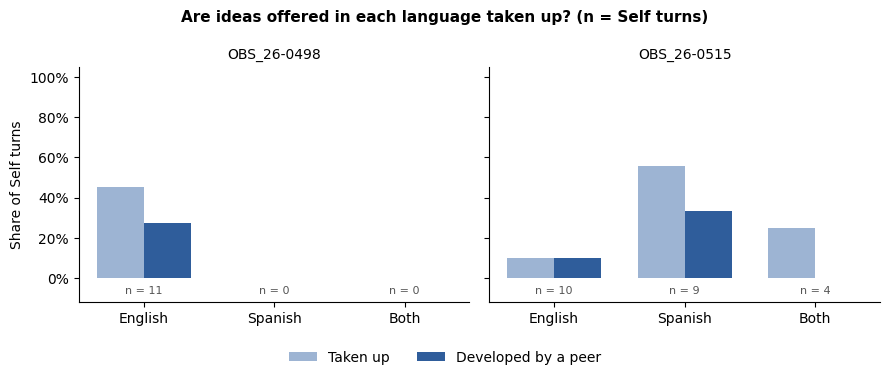

In [10]:
figure, axes = plt.subplots(1, len(observations), figsize=(4.5 * len(observations), 3.6), sharey=True, squeeze=False)
width = 0.36
for axis, observation in zip(axes[0], observations):
    shown = language_summary[language_summary["Observation"] == observation].set_index("Language").reindex(LANGUAGES)
    x = np.arange(len(LANGUAGES))
    axis.bar(x - width / 2, shown["taken_up_rate"].fillna(0), width, color=COLORS["acknowledged"], label="Taken up")
    axis.bar(x + width / 2, shown["developed_rate"].fillna(0), width, color=COLORS["developed"], label="Developed by a peer")
    for position, language in zip(x, LANGUAGES):
        n = shown.loc[language, "Self turns"]
        axis.text(position, -0.08, "n = 0" if pd.isna(n) else f"n = {int(n)}", ha="center", fontsize=8, color="#555555")
    axis.set_xticks(x)
    axis.set_xticklabels(LANGUAGES)
    axis.set_ylim(-0.12, 1.05)
    axis.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}" if value >= 0 else ""))
    axis.set_title(observation, fontsize=10)
    axis.spines[["top", "right"]].set_visible(False)
axes[0][0].set_ylabel("Share of Self turns")
handles, labels = axes[0][0].get_legend_handles_labels()
figure.legend(handles, labels, loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.04))
figure.suptitle("Are ideas offered in each language taken up? (n = Self turns)", fontsize=11, weight="bold")
figure.tight_layout(rect=(0, 0.06, 1, 1))
figure.savefig(OUTPUT_DIR / "language_uptake_bars.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. LLM-coded uptake and GCA

Does GCA's semantic-similarity signal line up with the uptake the LLM codes? Each point is one student in one observation:

- **Social impact** (how similar peers' next few contributions are to this student's) against **uptake received per Self turn**, both about whether a student's ideas are taken up.
- **Responsivity** (how similar this student's contributions are to peers' previous ones) against the **share of the student's turns coded Other**, both about whether a student builds on others.

We report Spearman's rank correlation with the number of points. With only a few students the correlation is not meaningful; it becomes informative once the LLM codes cover many observations.

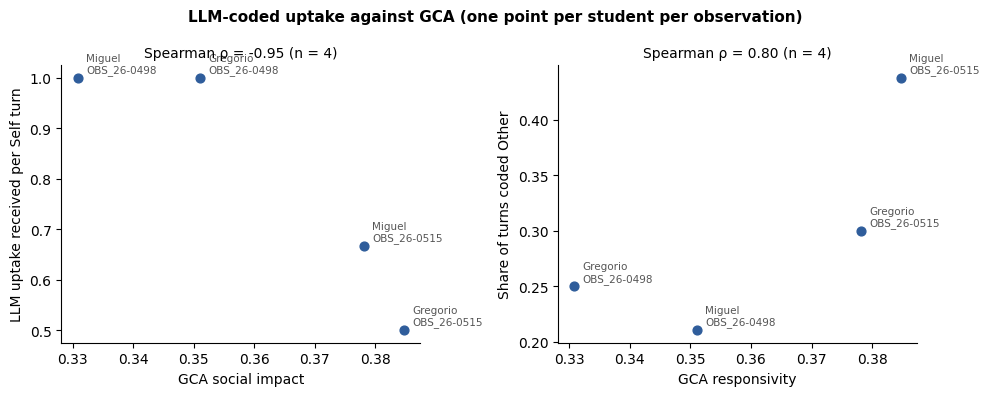

,GCA measure,LLM measure,points,Spearman rho
0,GCA social impact,LLM uptake received per Self turn,4,-0.95
1,GCA responsivity,Share of turns coded Other,4,0.80


In [11]:
if not GCA_SCORES.exists():
    print(f"{GCA_SCORES} not found: run 'A3 - Methods.ipynb' with REPRESENTATION = 'embeddings' first.")
else:
    gca = pd.read_csv(GCA_SCORES)[["observation", "speaker", "social_impact", "overall_responsivity"]]
    compared = students.merge(gca, on=["observation", "speaker"], how="inner")
    compared["uptake_per_self_turn"] = compared["uptake_received"] / compared["self_turns"].replace(0, np.nan)
    compared["other_share"] = compared["other_turns"] / compared["turns"]
    compared.to_csv(OUTPUT_DIR / "gca_comparison.csv", index=False)

    PAIRS = [("social_impact", "uptake_per_self_turn", "GCA social impact", "LLM uptake received per Self turn"),
             ("overall_responsivity", "other_share", "GCA responsivity", "Share of turns coded Other")]
    figure, axes = plt.subplots(1, 2, figsize=(10, 4))
    correlations = []
    for axis, (x_column, y_column, x_label, y_label) in zip(axes, PAIRS):
        shown = compared.dropna(subset=[x_column, y_column])
        axis.scatter(shown[x_column], shown[y_column], s=40, color="#2f5d9b", zorder=3)
        for _, point in shown.iterrows():
            axis.annotate(f"{point['speaker']}\n{point['observation']}", (point[x_column], point[y_column]),
                          textcoords="offset points", xytext=(6, 4), fontsize=7.5, color="#555555")
        rho = shown[x_column].corr(shown[y_column], method="spearman") if len(shown) > 2 else np.nan
        correlations.append({"GCA measure": x_label, "LLM measure": y_label, "points": len(shown),
                             "Spearman rho": round(rho, 2) if not pd.isna(rho) else ""})
        axis.set_xlabel(x_label)
        axis.set_ylabel(y_label)
        axis.set_title(f"Spearman ρ = {rho:.2f} (n = {len(shown)})" if not pd.isna(rho) else f"n = {len(shown)}",
                       fontsize=10)
        axis.spines[["top", "right"]].set_visible(False)
    figure.suptitle("LLM-coded uptake against GCA (one point per student per observation)", fontsize=11, weight="bold")
    figure.tight_layout()
    figure.savefig(OUTPUT_DIR / "gca_comparison.png", dpi=200, bbox_inches="tight")
    plt.show()

    correlations = pd.DataFrame(correlations)
    correlations.to_csv(OUTPUT_DIR / "gca_correlations.csv", index=False)
    display(correlations)

## Outputs

All files are in `results/uptake_participation/` and contain codes, counts, and scores only, no transcript text.

| File | Contents |
|---|---|
| `turns.csv` | Every student turn with its Whose, Level, language, and whether a peer took it up |
| `uptake_events.csv` | Every uptake event: source, responder, Level, and the languages of both turns |
| `builds_on_parse_log.csv` | `builds_on` values that named no row, or named a different speaker than the transcript |
| `students.csv` | Per-student counts and shares for each observation |
| `uptake_by_student.png`, `uptake_by_student_bars.png` | Whose ideas are taken up |
| `uptake_matrix.csv`, `uptake_network.png` | Who builds on whom |
| `gini.csv`, `gini.png`, `participation_shares.png` | How participation is distributed |
| `language_uptake.csv`, `language_uptake.png`, `language_uptake_bars.png`, `language_pairs.csv` | Uptake by language |
| `gca_comparison.csv`, `gca_comparison.png`, `gca_correlations.csv` | LLM-coded uptake against GCA |